# Capítulo 4 — Ensayos y Resultados (Notebook de análisis)

Esta notebook está diseñada para **extraer conclusiones y tablas/gráficos** para la redacción, sin generar CSVs nuevos.

## Estructura
- **4.1 Configuración experimental**
- **4.2 Resultados de los modelos predictivos (LSTM + GJR-GARCH)**
- **4.3 Impacto en la optimización de portafolios**
- **4.4 Discusión de resultados (plantilla guiada)**


In [3]:
from pathlib import Path
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 180)
sns.set_style('whitegrid')


In [69]:
# --- Parámetros principales del análisis ---
ROOT = Path('/workspace/Markowitz')

# Corrida LSTM definitiva indicada por vos
LSTM_FINAL_RUN_ID = '20260419_214940'
LSTM_DIR = ROOT / 'outputs' / 'lstm_lab' / 'runs'

# Umbral de uso de predicción en el optimizador ai_returns_lstm
LSTM_DIR_ACC_THRESHOLD = 0.52

# Corridas de optimización a comparar (misma ponderación objetivo)
OPTIMIZATION_RUNS = {
    'Classic': {'run_id': 24, 'mlflow_run_id': '461fc6029f5d41639f0b20271c769903'},
    'LSTM': {'run_id': 25, 'mlflow_run_id': '6f3ec79561ea4be9a9995ca294e4ff6b'},
    'GRJ GARCH': {'run_id': 26, 'mlflow_run_id': '9a20f4ded8034debb61fadaabcc4ff51'},
}

TARGET_BLOCKS = {
    'AR': 0.20,
    'US': 0.50,
    'FUNDS_EQUITY': 0.12,
    'FUNDS_BONDS': 0.10,
    'GOLD': 0.08,
}

DB_PATH = ROOT / 'storage' / 'markowitz_app.db'


## 4.1 Configuración experimental

### Diagrama del pipeline experimental (texto)

```text
Data/returns.csv + metadata.csv
        │
        ├── Modelos IA
        │   ├── LSTM retornos -> outputs/lstm_lab/runs/<run_id>/...
        │   └── GJR-GARCH volatilidad -> outputs/predictions/volatility_predictions.csv
        │
        ├── Constructor de inputs de optimización
        │   ├── Classic: mu/cov históricos
        │   ├── ai_returns_lstm: mu LSTM (si dir_acc_test > 0.52) + fallback histórico
        │   └── ai_volatility: mu histórico + sigma con vol GJR-GARCH
        │
        └── Optimización Markowitz por bloques
            └── métricas, pesos, frontera, exposición
```


In [70]:
# Dataset base y tabla de activos
# Esta celda funciona aunque ROOT no exista o esté mal seteado.
from pathlib import Path
import os

# 1) Resolver ruta a returns.csv
returns_candidates = []

# a) Si existe ROOT, usarlo primero
if 'ROOT' in globals() and ROOT is not None:
    returns_candidates.append(Path(ROOT) / 'Data' / 'returns.csv')

# b) Variable de entorno opcional
env_root = os.getenv('MARKOWITZ_ROOT')
if env_root:
    returns_candidates.append(Path(env_root) / 'Data' / 'returns.csv')

# c) CWD + padres (para ejecutar notebook desde subcarpetas)
cwd = Path.cwd().resolve()
returns_candidates.extend([(cwd / 'Data' / 'returns.csv'), *[(p / 'Data' / 'returns.csv') for p in cwd.parents]])

# d) Rutas típicas
auto_roots = [
    Path('/workspace/Markowitz'),
    Path('/content/Markowitz'),
    Path.home() / 'Markowitz',
]
returns_candidates.extend([r / 'Data' / 'returns.csv' for r in auto_roots])

returns_path = next((p for p in returns_candidates if p.exists()), None)
if returns_path is None:
    raise FileNotFoundError(
        'No se encontró returns.csv. Definí MARKOWITZ_ROOT o seteá ROOT con la carpeta del repo Markowitz.'
    )

ROOT = returns_path.parent.parent
print(f'ROOT usado en esta celda: {ROOT}')

# 2) Cargar dataset base
returns = pd.read_csv(returns_path, parse_dates=['Date'])

# 3) Cargar metadata con compatibilidad de nombres
metadata_path_candidates = [
    ROOT / 'Data' / 'assets_metadata.csv',
    ROOT / 'Data' / 'asset_metadata.csv',  # compatibilidad por si cambia el nombre
]
metadata_path = next((p for p in metadata_path_candidates if p.exists()), None)
if metadata_path is None:
    raise FileNotFoundError('No se encontró assets_metadata.csv (ni asset_metadata.csv) dentro de Data/.')

metadata = pd.read_csv(metadata_path)
assets_table = metadata[['ticker', 'asset_class', 'block']].sort_values(['block', 'ticker']).reset_index(drop=True)

dataset_summary = pd.DataFrame([{
    'repo_root': str(ROOT),
    'archivo_returns': returns_path.name,
    'archivo_metadata': metadata_path.name,
    'fecha_inicio': returns['Date'].min().date().isoformat(),
    'fecha_fin': returns['Date'].max().date().isoformat(),
    'n_filas_retornos': int(len(returns)),
    'n_activos': int(metadata['ticker'].nunique()),
    'n_bloques': int(metadata['block'].nunique()),
}])

print('Resumen del dataset:')
display(dataset_summary)
print('\nTabla de activos (base para tesis):')
display(assets_table)

ROOT usado en esta celda: C:\Users\lucas\OneDrive\Documentos\GitHub\Markowitz
Resumen del dataset:


,repo_root,archivo_returns,archivo_metadata,fecha_inicio,fecha_fin,n_filas_retornos,n_activos,n_bloques
0,C:\Users\lucas\OneDrive\Documentos\GitHub\Mark...,returns.csv,assets_metadata.csv,2018-01-03,2025-12-31,2061,40,5



Tabla de activos (base para tesis):


,ticker,asset_class,block
0,ALUA.BA,Argentina Equity,AR
1,BBAR.BA,Argentina Equity,AR
2,BMA.BA,Argentina Equity,AR
3,CEPU.BA,Argentina Equity,AR
4,COME.BA,Argentina Equity,AR
5,EDN.BA,Argentina Equity,AR
6,GGAL.BA,Argentina Equity,AR
7,LOMA.BA,Argentina Equity,AR
8,PAMP.BA,Argentina Equity,AR
9,SUPV.BA,Argentina Equity,AR


In [71]:
# División train/val/test de la corrida LSTM definitiva
# Esta celda funciona aunque LSTM_DIR no exista o esté mal seteado.
from pathlib import Path
import os

run_id = str(LSTM_FINAL_RUN_ID)
metrics_candidates = []

# a) Ruta directa por LSTM_DIR (si existe)
if 'LSTM_DIR' in globals() and LSTM_DIR is not None:
    metrics_candidates.append(Path(LSTM_DIR) / run_id / 'metrics.csv')

# b) Ruta directa por ROOT (si existe)
if 'ROOT' in globals() and ROOT is not None:
    metrics_candidates.append(Path(ROOT) / 'outputs' / 'lstm_lab' / 'runs' / run_id / 'metrics.csv')

# c) Variable de entorno opcional
env_root = os.getenv('MARKOWITZ_ROOT')
if env_root:
    metrics_candidates.append(Path(env_root) / 'outputs' / 'lstm_lab' / 'runs' / run_id / 'metrics.csv')

# d) CWD + padres
cwd = Path.cwd().resolve()
metrics_candidates.extend([
    (cwd / 'outputs' / 'lstm_lab' / 'runs' / run_id / 'metrics.csv'),
    *[(p / 'outputs' / 'lstm_lab' / 'runs' / run_id / 'metrics.csv') for p in cwd.parents],
])

# e) Rutas típicas
auto_roots = [
    Path('/workspace/Markowitz'),
    Path('/content/Markowitz'),
    Path.home() / 'Markowitz',
]
metrics_candidates.extend([r / 'outputs' / 'lstm_lab' / 'runs' / run_id / 'metrics.csv' for r in auto_roots])

metrics_path = next((p for p in metrics_candidates if p.exists()), None)
if metrics_path is None:
    raise FileNotFoundError(
        f'No se encontró metrics.csv para run_id={run_id}. '
        'Verificá MARKOWITZ_ROOT o que exista outputs/lstm_lab/runs/<run_id>/metrics.csv.'
    )

# Mantener ROOT/LSTM_DIR consistentes para celdas siguientes
ROOT = metrics_path.parents[4]
LSTM_DIR = ROOT / 'outputs' / 'lstm_lab' / 'runs'
print(f'Métricas LSTM leídas desde: {metrics_path}')

final_metrics = pd.read_csv(metrics_path)

required_cols = ['n_train', 'n_val', 'n_test']
missing = [c for c in required_cols if c not in final_metrics.columns]
if missing:
    raise ValueError(f'Faltan columnas en metrics.csv: {missing}. Columnas disponibles: {list(final_metrics.columns)}')

split_summary = pd.DataFrame([{
    'run_id': run_id,
    'metrics_path': str(metrics_path),
    'n_tickers': int(len(final_metrics)),
    'n_train_promedio': float(final_metrics['n_train'].mean()),
    'n_val_promedio': float(final_metrics['n_val'].mean()),
    'n_test_promedio': float(final_metrics['n_test'].mean()),
    'n_train_min': int(final_metrics['n_train'].min()),
    'n_train_max': int(final_metrics['n_train'].max()),
    'n_val_min': int(final_metrics['n_val'].min()),
    'n_val_max': int(final_metrics['n_val'].max()),
    'n_test_min': int(final_metrics['n_test'].min()),
    'n_test_max': int(final_metrics['n_test'].max()),
}])

display(split_summary)


Métricas LSTM leídas desde: C:\Users\lucas\OneDrive\Documentos\GitHub\Markowitz\outputs\lstm_lab\runs\20260419_214940\metrics.csv


,run_id,metrics_path,n_tickers,n_train_promedio,n_val_promedio,n_test_promedio,n_train_min,n_train_max,n_val_min,n_val_max,n_test_min,n_test_max
0,20260419_214940,C:\Users\lucas\OneDrive\Documentos\GitHub\Mark...,40,677.0,145.0,146.0,677,677,145,145,146,146


## 4.2 Resultados de los modelos predictivos

In [72]:
# Historial de corridas LSTM desde outputs/lstm_lab/runs/*
rows = []
for run_path in sorted(LSTM_DIR.glob('*')):
    summary_path = run_path / 'summary.json'
    metrics_path = run_path / 'metrics.csv'
    if not summary_path.exists() or not metrics_path.exists():
        continue
    summary = json.loads(summary_path.read_text())
    metrics = pd.read_csv(metrics_path)
    rows.append({
        'run_id': summary.get('run_id', run_path.name),
        'forecast_horizon': summary.get('forecast_horizon'),
        'target_aggregation': summary.get('target_aggregation'),
        'seq_len': summary.get('seq_len'),
        'epochs': summary.get('epochs'),
        'batch_size': summary.get('batch_size'),
        'lr': summary.get('lr'),
        'hidden_size': summary.get('hidden_size'),
        'num_layers': summary.get('num_layers'),
        'dropout': summary.get('dropout'),
        'tickers_with_predictions': summary.get('tickers_with_predictions', len(metrics)),
        'mean_rmse_test': float(metrics['rmse_test'].mean()),
        'mean_dir_acc_test': float(metrics['dir_acc_test'].mean()),
        'share_dir_acc_gt_052': float((metrics['dir_acc_test'] > LSTM_DIR_ACC_THRESHOLD).mean()),
    })

lstm_history = pd.DataFrame(rows).sort_values('run_id', ascending=False).reset_index(drop=True)

print('Historial LSTM (ordenado por run_id desc):')
display(lstm_history)

print('Top corridas por dir_acc_test (desempate: menor rmse_test):')
display(lstm_history.sort_values(['mean_dir_acc_test', 'mean_rmse_test'], ascending=[False, True]).head(10))


Historial LSTM (ordenado por run_id desc):


,run_id,forecast_horizon,target_aggregation,seq_len,epochs,batch_size,lr,hidden_size,num_layers,dropout,tickers_with_predictions,mean_rmse_test,mean_dir_acc_test,share_dir_acc_gt_052
0,20260419_214940,5,mean,40,50,32,0.001,64,2,0.2,40,0.009811,0.529795,0.55
1,20260329_012341,1,mean,40,50,32,0.001,64,2,0.2,40,0.021302,0.503082,0.40
2,20260329_005921,1,mean,40,50,32,0.001,64,2,0.2,40,0.022277,0.500166,0.25
3,20260329_004351,1,mean,60,50,32,0.001,64,2,0.2,40,0.021097,0.499176,0.25
4,20260328_234602,1,mean,40,50,32,0.001,64,2,0.2,40,0.021374,0.502397,0.40
5,20260322_025355,5,mean,40,50,32,0.001,64,2,0.2,40,0.009852,0.496747,0.35
6,20260313_034246,5,mean,40,50,32,0.001,64,2,0.2,40,0.009651,0.535788,0.55


Top corridas por dir_acc_test (desempate: menor rmse_test):


,run_id,forecast_horizon,target_aggregation,seq_len,epochs,batch_size,lr,hidden_size,num_layers,dropout,tickers_with_predictions,mean_rmse_test,mean_dir_acc_test,share_dir_acc_gt_052
6,20260313_034246,5,mean,40,50,32,0.001,64,2,0.2,40,0.009651,0.535788,0.55
0,20260419_214940,5,mean,40,50,32,0.001,64,2,0.2,40,0.009811,0.529795,0.55
1,20260329_012341,1,mean,40,50,32,0.001,64,2,0.2,40,0.021302,0.503082,0.40
4,20260328_234602,1,mean,40,50,32,0.001,64,2,0.2,40,0.021374,0.502397,0.40
2,20260329_005921,1,mean,40,50,32,0.001,64,2,0.2,40,0.022277,0.500166,0.25
3,20260329_004351,1,mean,60,50,32,0.001,64,2,0.2,40,0.021097,0.499176,0.25
5,20260322_025355,5,mean,40,50,32,0.001,64,2,0.2,40,0.009852,0.496747,0.35


In [73]:
# Parámetros y resultados de la corrida definitiva
final_summary = json.loads((LSTM_DIR / LSTM_FINAL_RUN_ID / 'summary.json').read_text())

final_params = pd.DataFrame([{
    'run_id': final_summary['run_id'],
    'start_date': final_summary.get('start_date'),
    'forecast_horizon': final_summary.get('forecast_horizon'),
    'target_aggregation': final_summary.get('target_aggregation'),
    'seq_len': final_summary.get('seq_len'),
    'epochs': final_summary.get('epochs'),
    'batch_size': final_summary.get('batch_size'),
    'lr': final_summary.get('lr'),
    'hidden_size': final_summary.get('hidden_size'),
    'num_layers': final_summary.get('num_layers'),
    'dropout': final_summary.get('dropout'),
    'selected_features': ', '.join(final_summary.get('selected_features', [])),
    'tickers_with_predictions': final_summary.get('tickers_with_predictions'),
    'mean_rmse_test_summary': final_summary.get('mean_rmse_test'),
    'mean_dir_acc_test_summary': final_summary.get('mean_dir_acc_test'),
}])

display(final_params)


,run_id,start_date,forecast_horizon,target_aggregation,seq_len,epochs,batch_size,lr,hidden_size,num_layers,dropout,selected_features,tickers_with_predictions,mean_rmse_test_summary,mean_dir_acc_test_summary
0,20260419_214940,2022-01-01,5,mean,40,50,32,0.001,64,2,0.2,"return, lag_1, lag_2, rolling_mean_5, rolling_...",40,0.009811,0.529795


In [74]:
# Activos que pasan y que no pasan el umbral 0.52 (uso de mu_pred vs fallback histórico)
final_eval = final_metrics[['ticker', 'mu_pred', 'rmse_test', 'dir_acc_test', 'corr_test']].copy()
final_eval['use_lstm_mu_pred'] = final_eval['dir_acc_test'] > LSTM_DIR_ACC_THRESHOLD

passed = final_eval[final_eval['use_lstm_mu_pred']].sort_values('dir_acc_test', ascending=False)
failed = final_eval[~final_eval['use_lstm_mu_pred']].sort_values('dir_acc_test', ascending=True)

summary_threshold = pd.DataFrame([{
    'run_id': LSTM_FINAL_RUN_ID,
    'threshold_dir_acc_test': LSTM_DIR_ACC_THRESHOLD,
    'total_activos': len(final_eval),
    'activos_que_pasan': int(len(passed)),
    'activos_con_fallback_historico': int(len(failed)),
    'porcentaje_que_pasan': float(len(passed) / len(final_eval)),
}])

print('Resumen umbral LSTM para optimización ai_returns_lstm:')
display(summary_threshold)

print('\nActivos que pasan (> 0.52):')
display(passed[['ticker', 'dir_acc_test', 'rmse_test', 'mu_pred']].reset_index(drop=True))

print('\nActivos con fallback a retorno histórico (<= 0.52):')
display(failed[['ticker', 'dir_acc_test', 'rmse_test', 'mu_pred']].reset_index(drop=True))


Resumen umbral LSTM para optimización ai_returns_lstm:


,run_id,threshold_dir_acc_test,total_activos,activos_que_pasan,activos_con_fallback_historico,porcentaje_que_pasan
0,20260419_214940,0.52,40,22,18,0.55



Activos que pasan (> 0.52):


,ticker,dir_acc_test,rmse_test,mu_pred
0,SPY,0.698630,0.002773,0.000614
1,GOOGL,0.671233,0.007940,0.000564
2,HYG,0.671233,0.000784,0.000306
3,QQQ,0.664384,0.003662,0.000984
4,XOM,0.643836,0.005580,0.000534
5,MSFT,0.630137,0.004576,0.000908
6,NVDA,0.623288,0.009651,0.001623
7,IWM,0.623288,0.004280,0.000285
8,TGNO4.BA,0.609589,0.020235,-0.006790
9,JPM,0.609589,0.004806,0.000749



Activos con fallback a retorno histórico (<= 0.52):


,ticker,dir_acc_test,rmse_test,mu_pred
0,BBAR.BA,0.328767,0.020144,0.003791
1,EDN.BA,0.397260,0.021982,0.000241
2,BMA.BA,0.424658,0.016975,0.002347
3,COME.BA,0.431507,0.024923,0.003173
4,IEF,0.431507,0.001259,-0.000341
5,SUPV.BA,0.438356,0.023381,-0.005944
6,YPFD.BA,0.438356,0.013404,-0.003921
7,TSLA,0.445205,0.019129,0.020000
8,TLT,0.452055,0.003453,-0.000944
9,GGAL.BA,0.452055,0.018488,0.001926


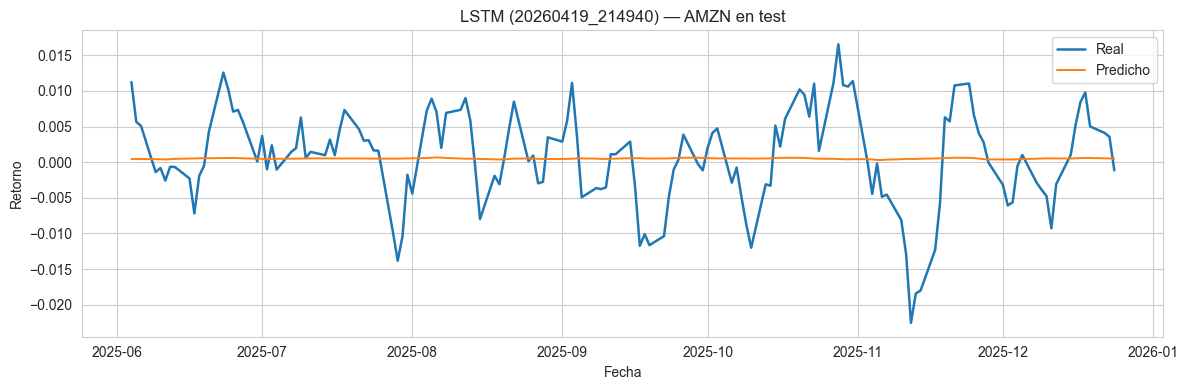

In [75]:
# Gráfico real vs predicho para un ticker ejemplo de la corrida definitiva
TICKER_EXAMPLE = 'AMZN'
pred_file = LSTM_DIR / LSTM_FINAL_RUN_ID / 'per_ticker' / f'{TICKER_EXAMPLE}_predictions.csv'

if pred_file.exists():
    pred = pd.read_csv(pred_file, parse_dates=['date'])
    pred_test = pred[pred['split'] == 'test'].copy()

    plt.figure(figsize=(12, 4))
    plt.plot(pred_test['date'], pred_test['y_true'], label='Real', linewidth=1.8)
    plt.plot(pred_test['date'], pred_test['y_pred'], label='Predicho', linewidth=1.4)
    plt.title(f'LSTM ({LSTM_FINAL_RUN_ID}) — {TICKER_EXAMPLE} en test')
    plt.xlabel('Fecha')
    plt.ylabel('Retorno')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f'No existe archivo por ticker: {pred_file}')


In [83]:
import pandas as pd
import numpy as np
from pathlib import Path

pred_dir = LSTM_DIR / LSTM_FINAL_RUN_ID / 'per_ticker'

rows = []

for pred_file in sorted(pred_dir.glob('*_predictions.csv')):
    ticker = pred_file.name.replace('_predictions.csv', '')

    pred = pd.read_csv(pred_file, parse_dates=['date'])
    pred_test = pred[pred['split'] == 'test'].copy()

    if pred_test.empty:
        continue

    std_y_true = pred_test['y_true'].std()
    std_y_pred = pred_test['y_pred'].std()

    amp_ratio = np.nan
    if pd.notna(std_y_true) and std_y_true != 0:
        amp_ratio = std_y_pred / std_y_true

    rows.append({
        'ticker': ticker,
        'n_test': len(pred_test),
        'std_y_true_test': std_y_true,
        'std_y_pred_test': std_y_pred,
        'amp_ratio': amp_ratio,
        'mean_y_true_test': pred_test['y_true'].mean(),
        'mean_y_pred_test': pred_test['y_pred'].mean(),
    })

amp_df = pd.DataFrame(rows).sort_values('amp_ratio')
amp_df

,ticker,n_test,std_y_true_test,std_y_pred_test,amp_ratio,mean_y_true_test,mean_y_pred_test
22,MSFT,146,0.004551,0.000011,0.002404,0.000301,0.000926
27,SPY,146,0.002753,0.000014,0.004965,0.001029,0.000619
5,BRK-B,146,0.003509,0.000018,0.005158,0.000124,0.000279
13,GOOGL,146,0.007235,0.000044,0.006120,0.003919,0.000560
18,KO,146,0.003518,0.000031,0.008902,-0.000070,0.000404
2,AMZN,146,0.006763,0.000068,0.010112,0.000651,0.000508
21,META,146,0.007045,0.000077,0.010994,-0.000141,0.000337
26,QQQ,146,0.003673,0.000043,0.011617,0.001126,0.001031
25,PEP,146,0.005106,0.000062,0.012231,0.000427,0.000298
34,UNH,146,0.009476,0.000139,0.014666,0.000236,0.000551


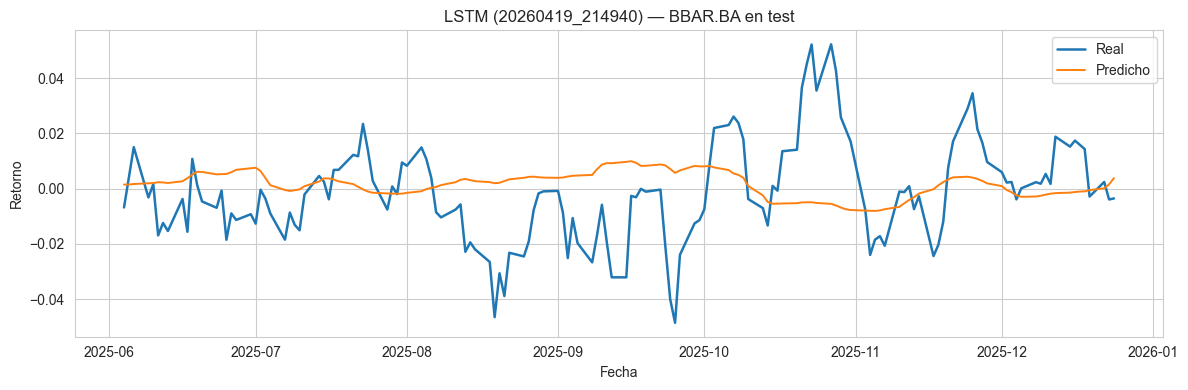

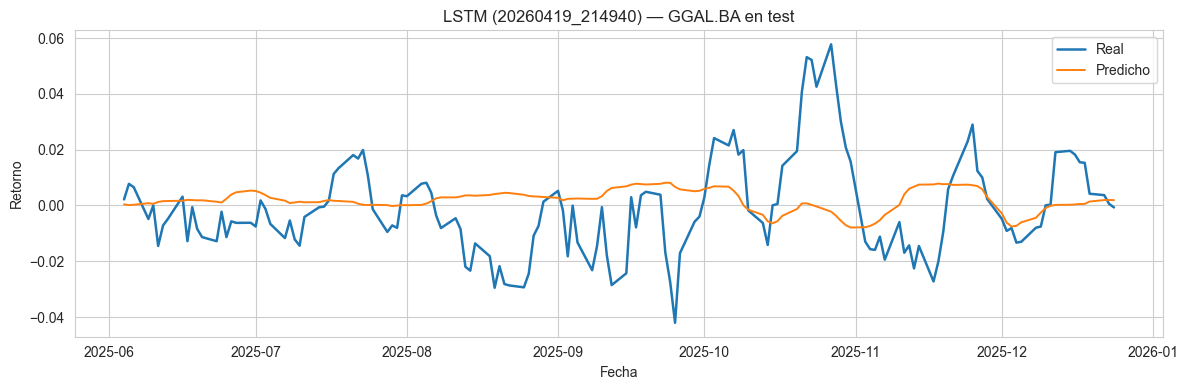

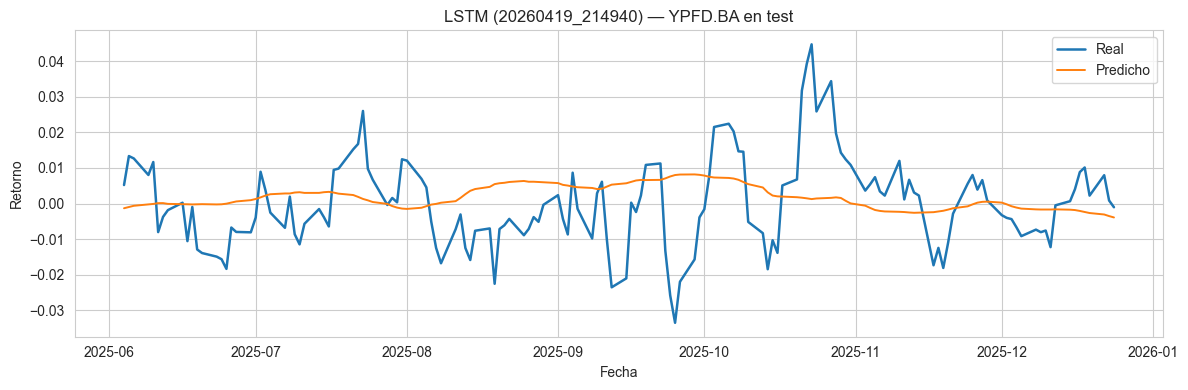

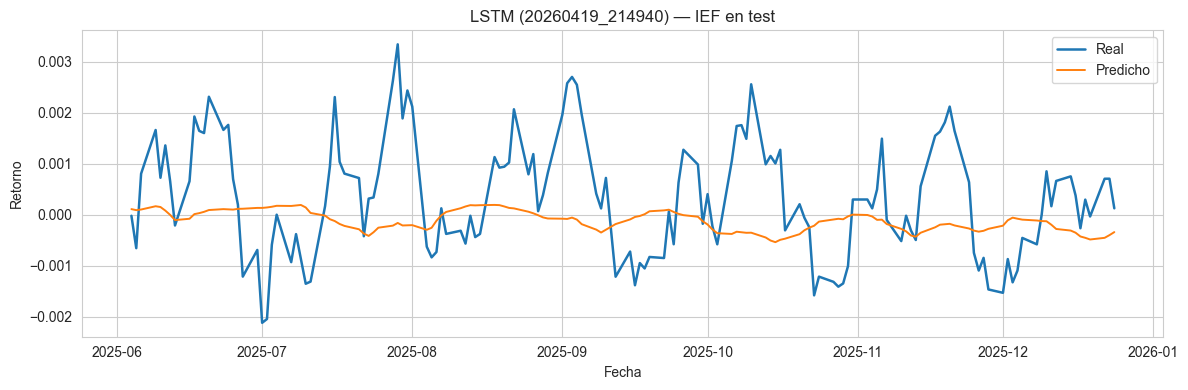

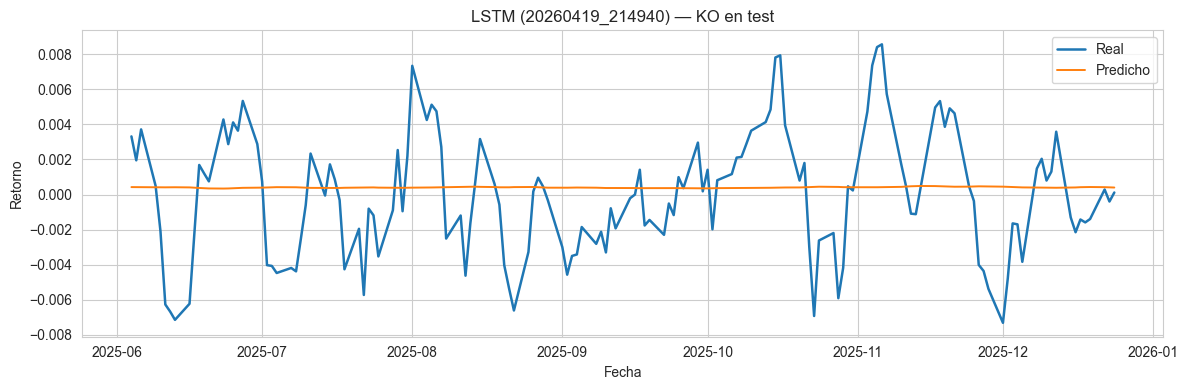

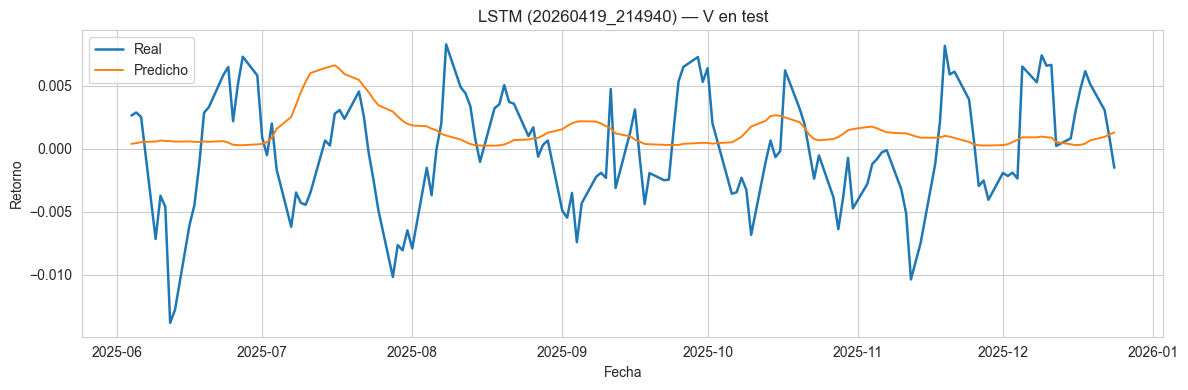

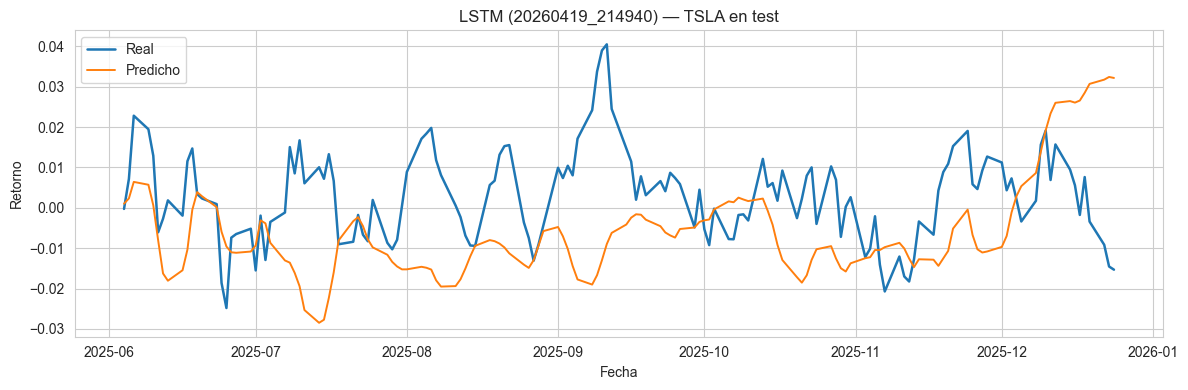

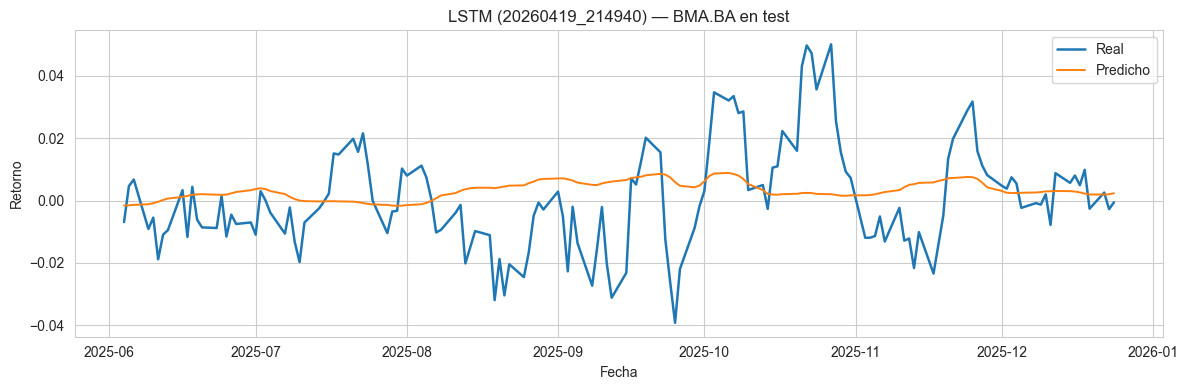

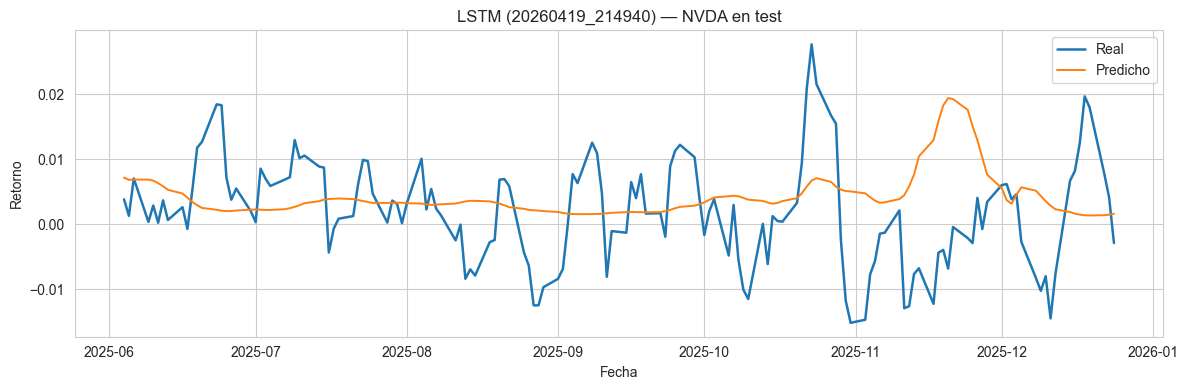

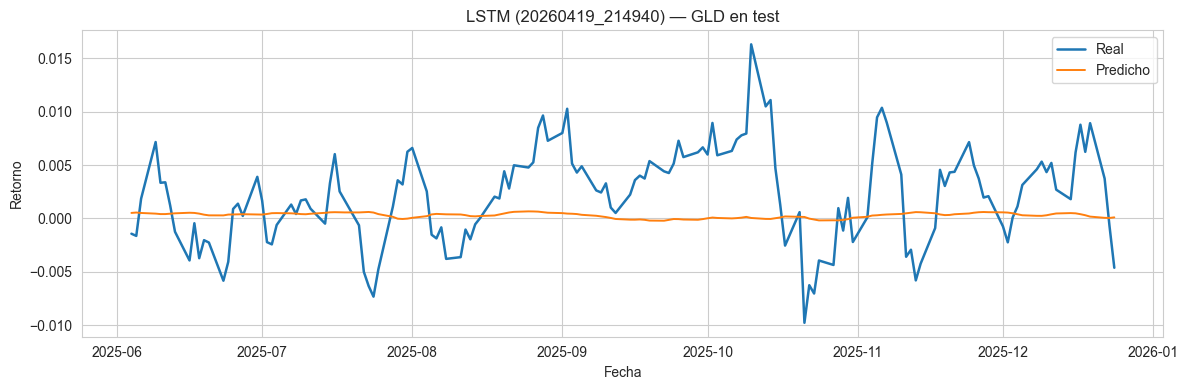

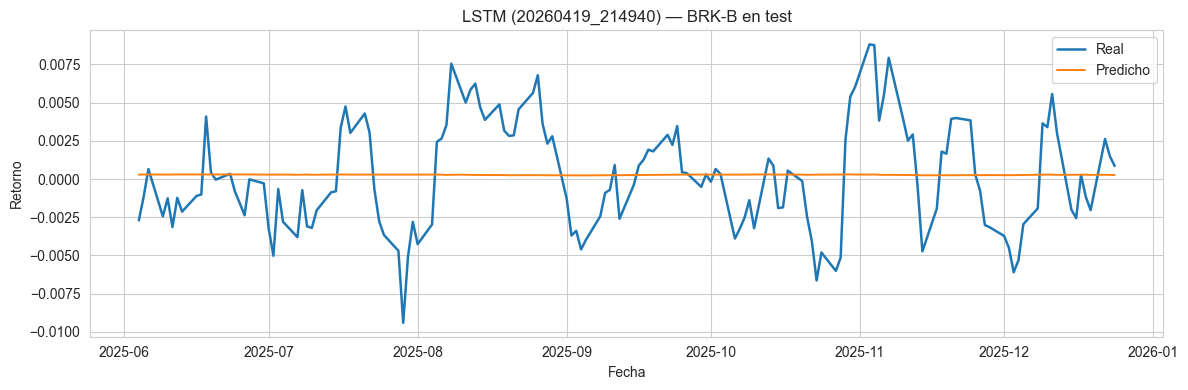

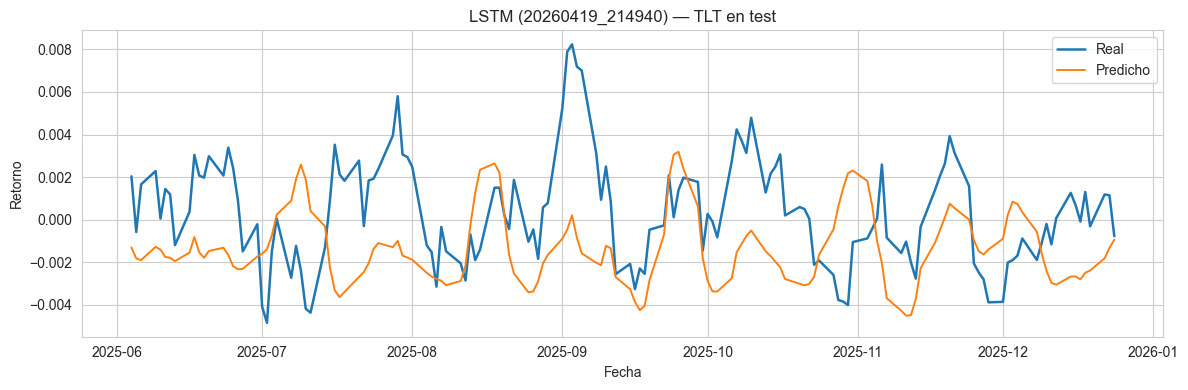

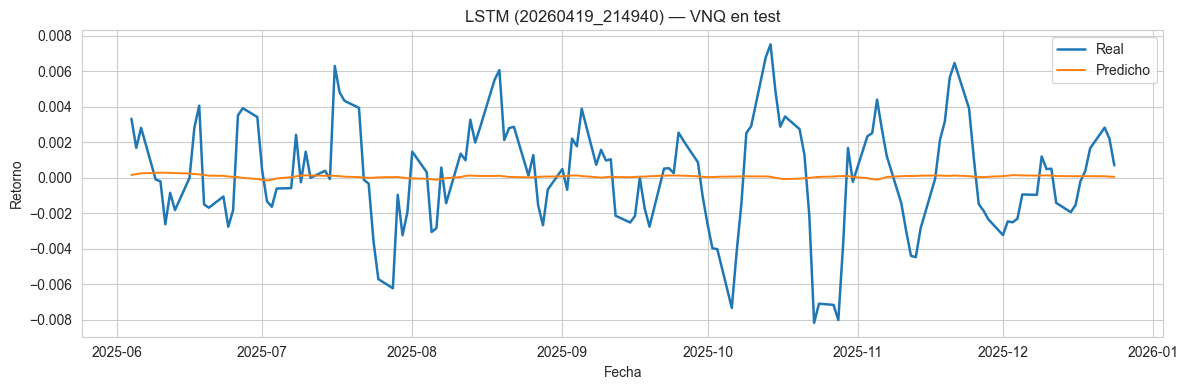

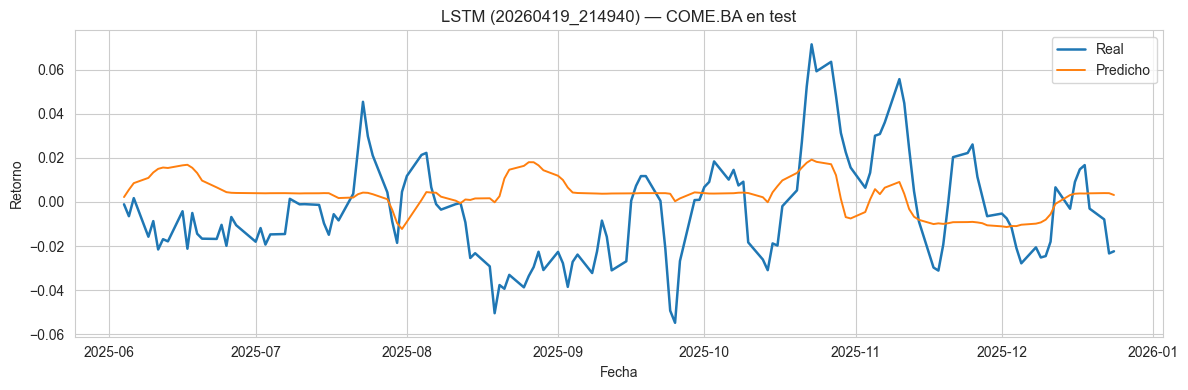

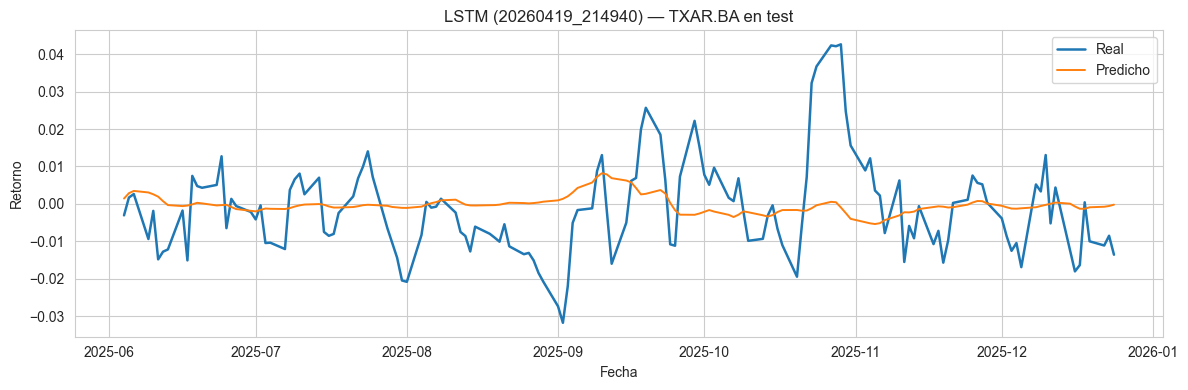

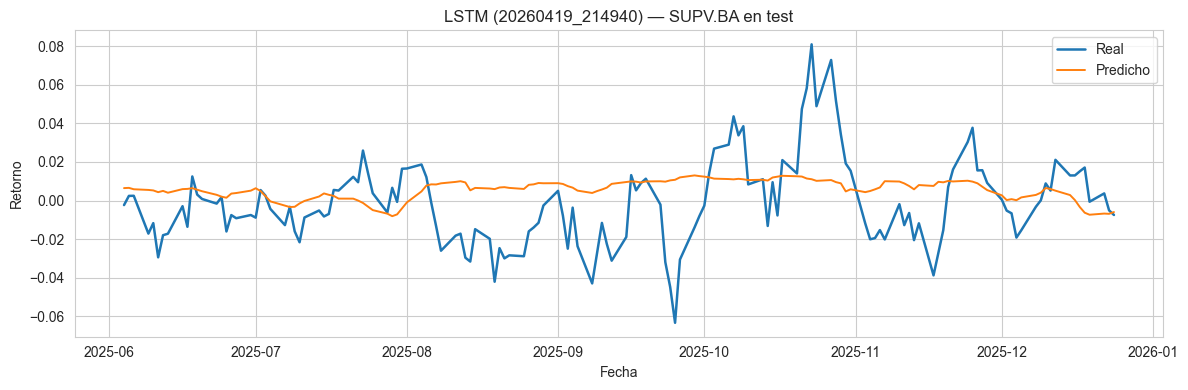

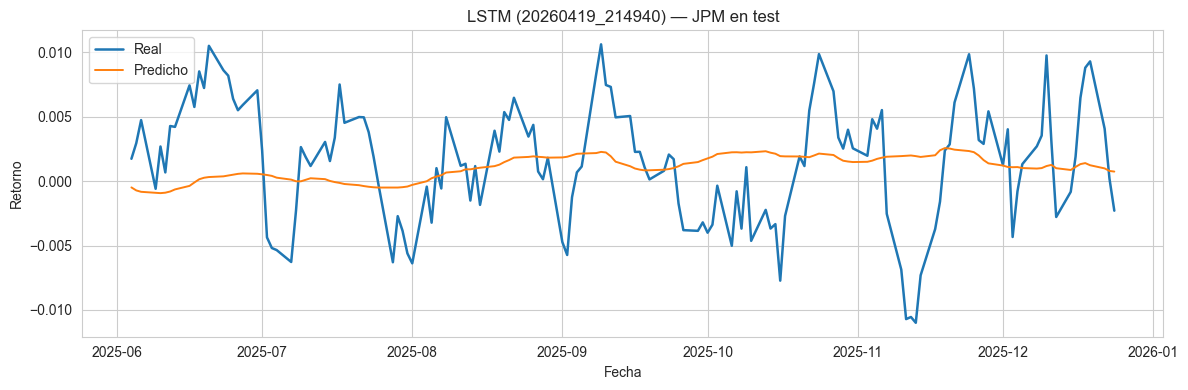

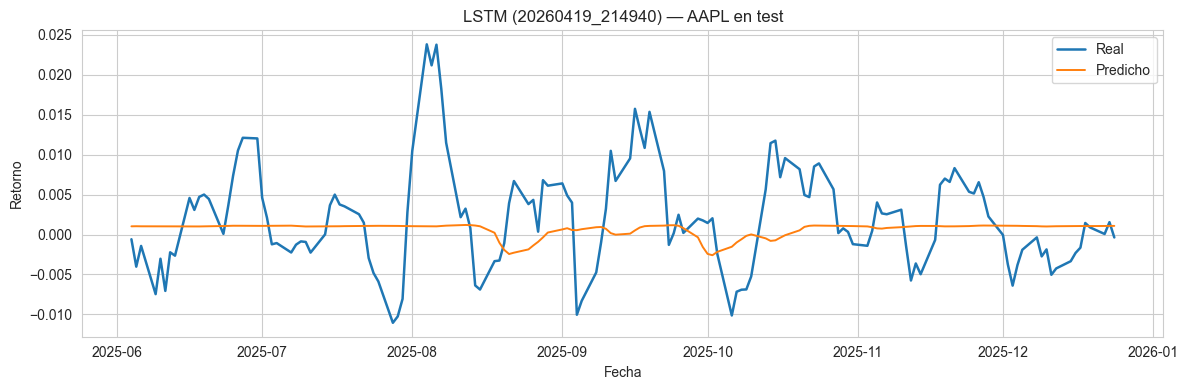

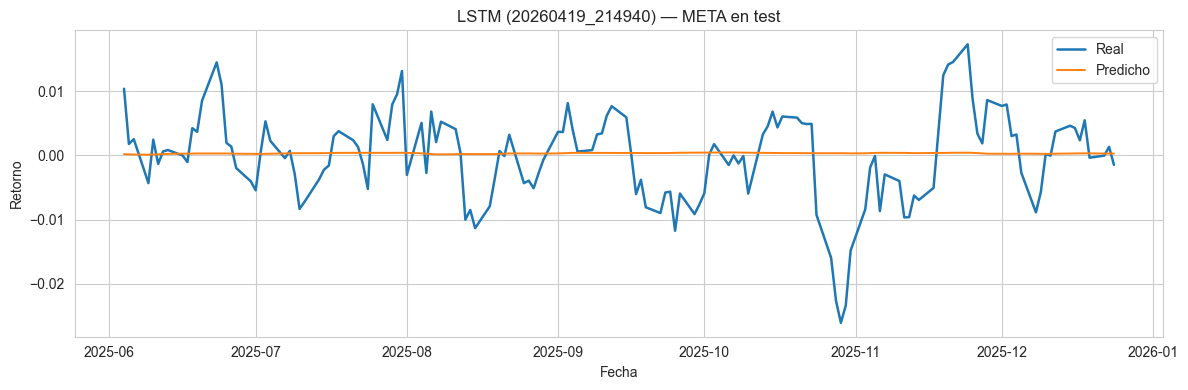

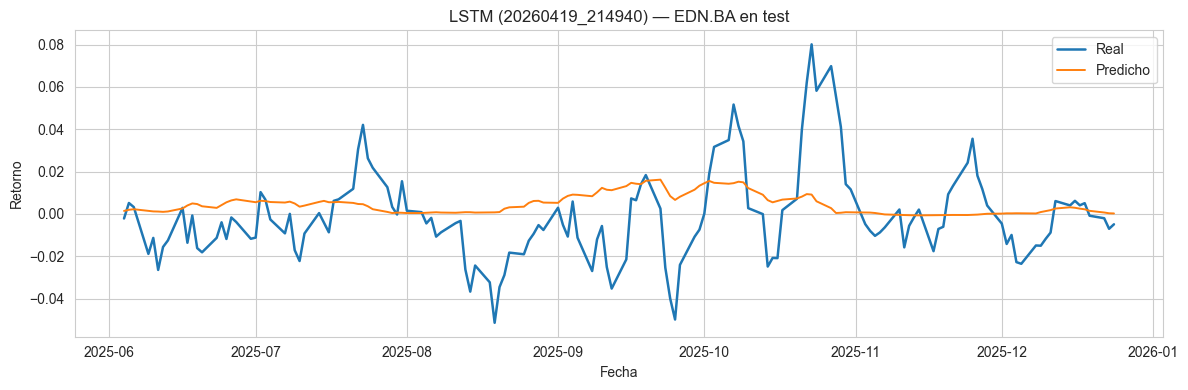

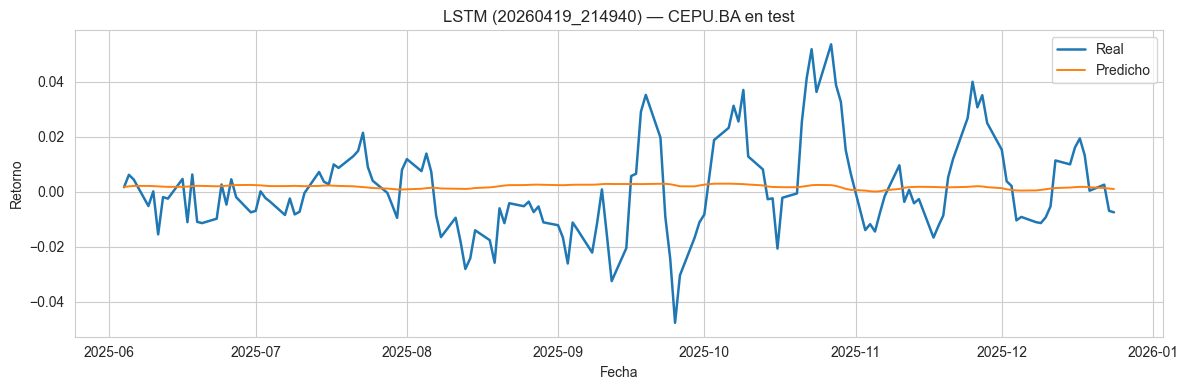

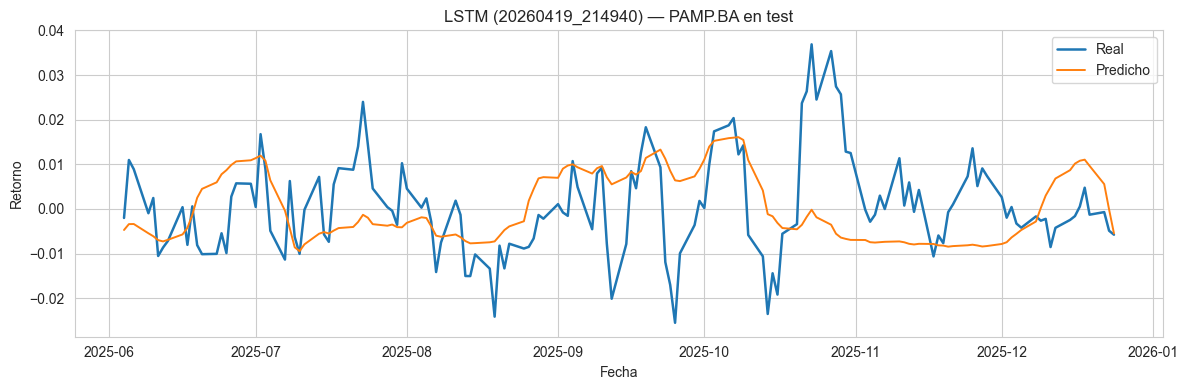

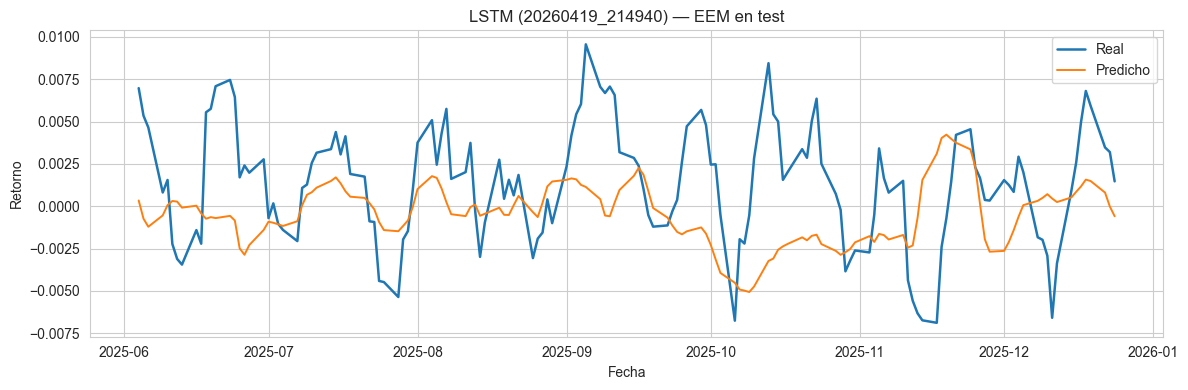

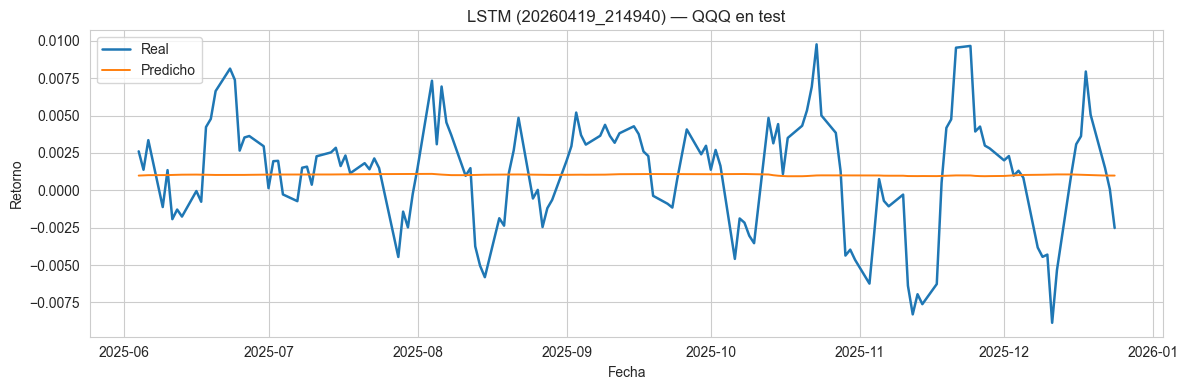

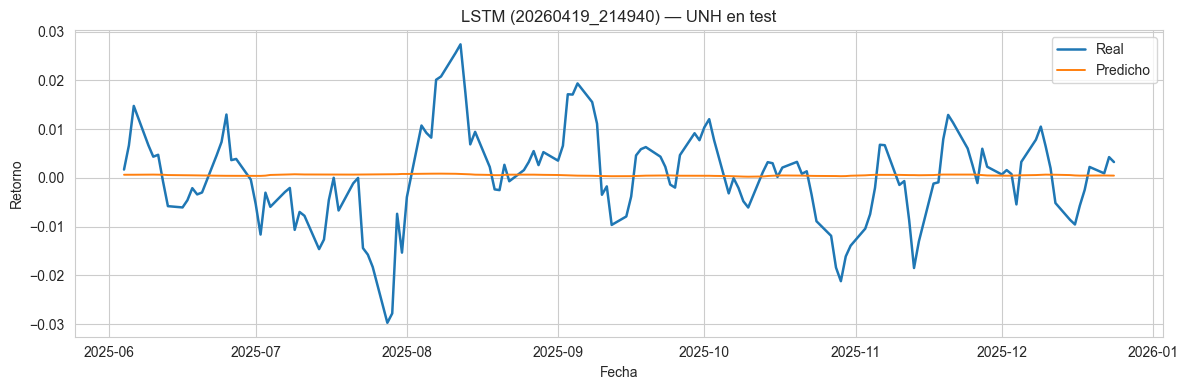

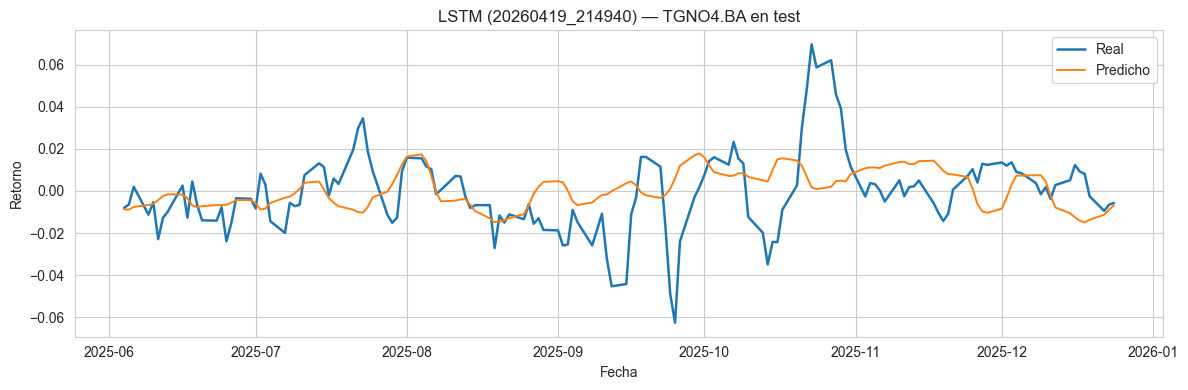

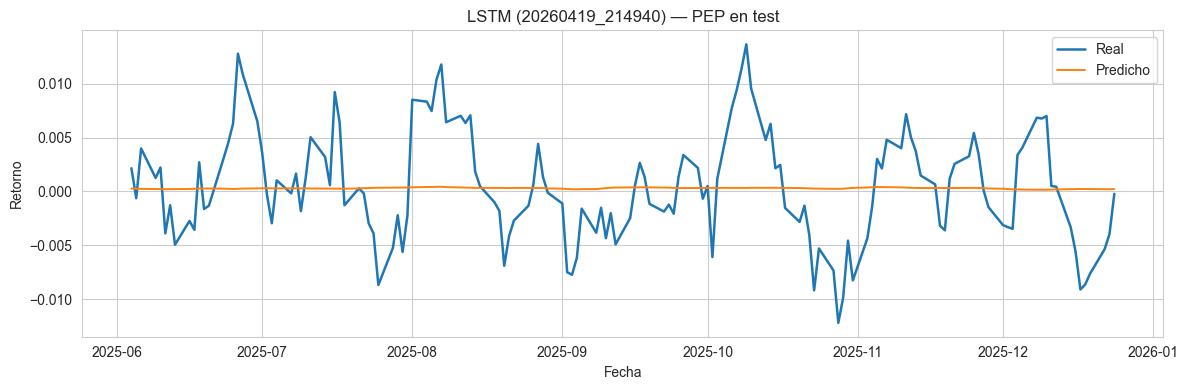

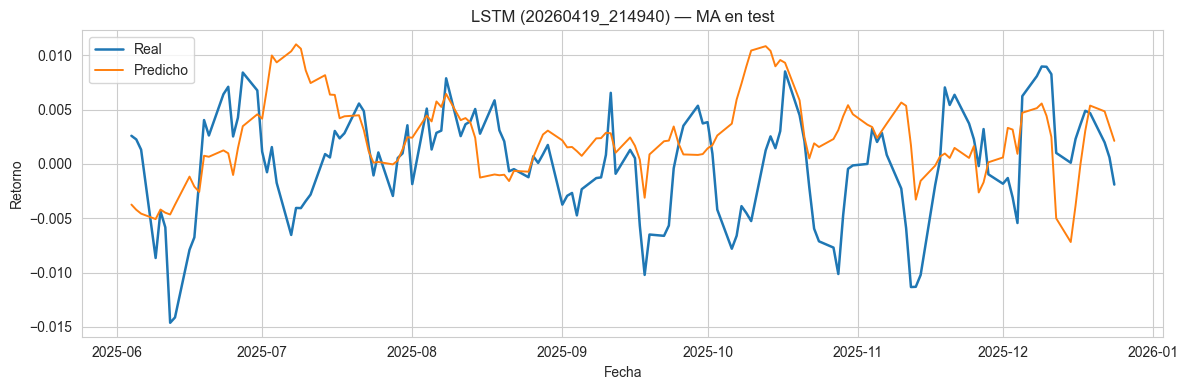

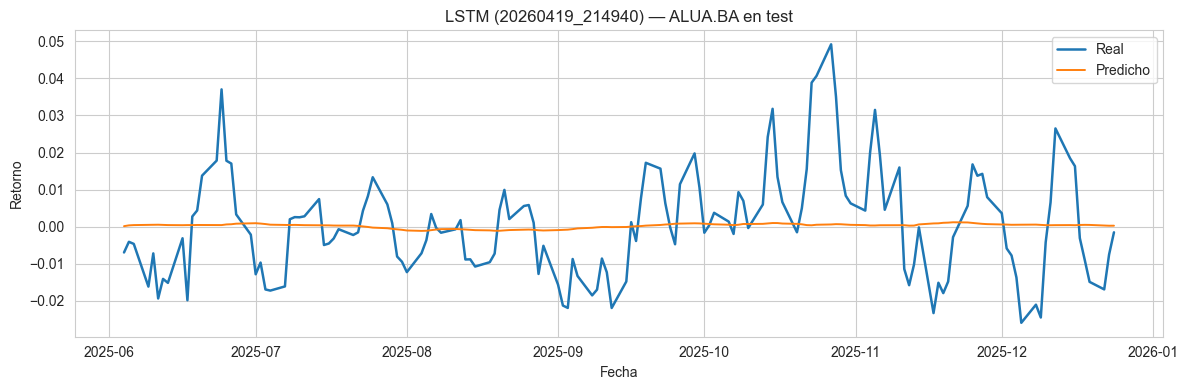

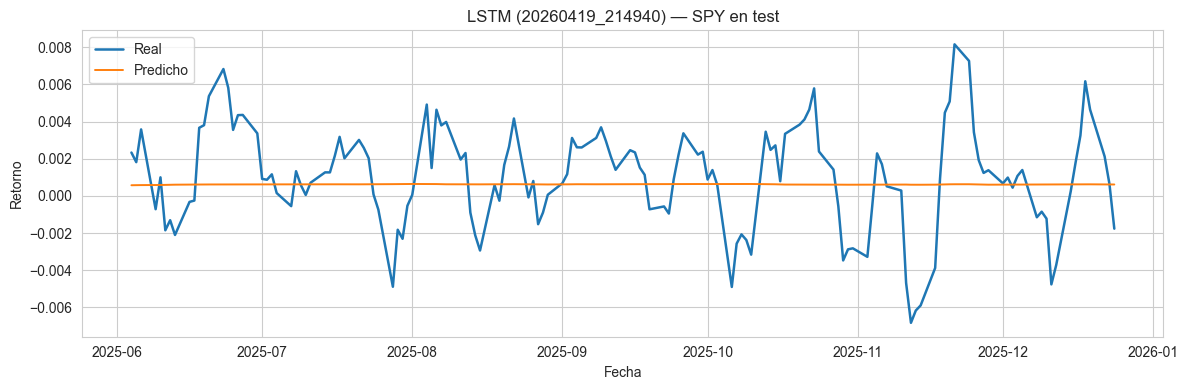

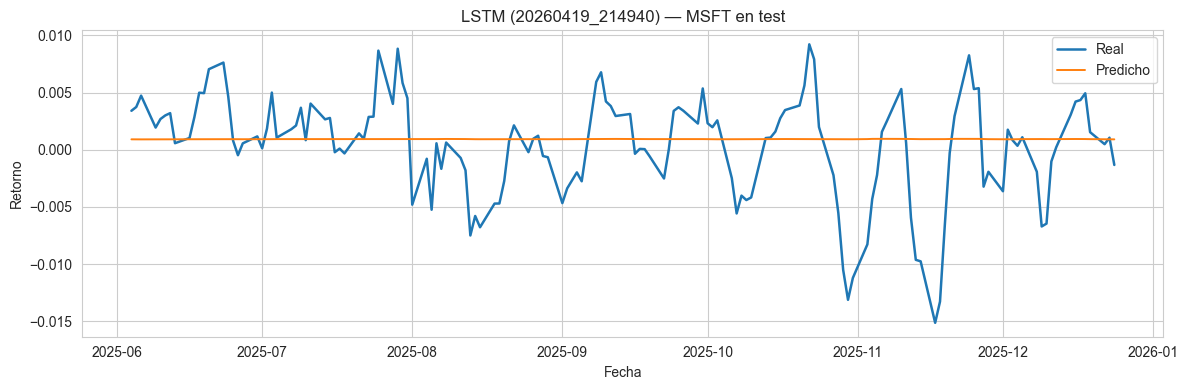

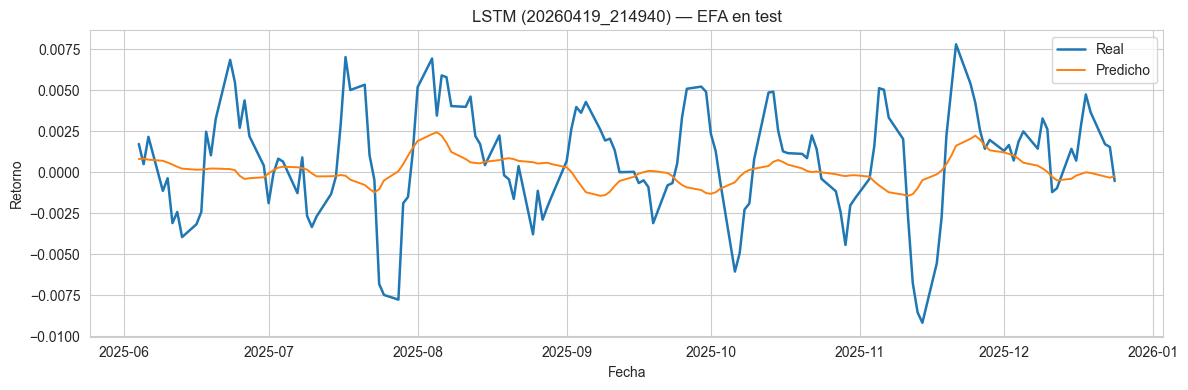

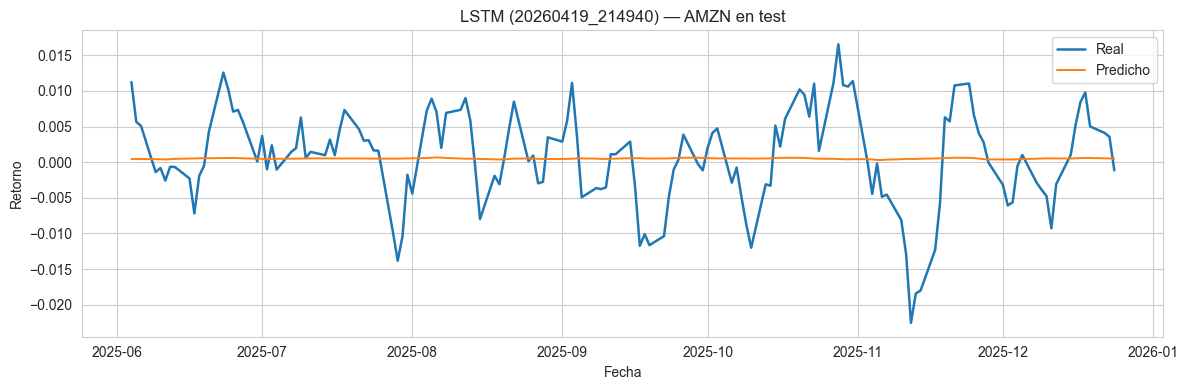

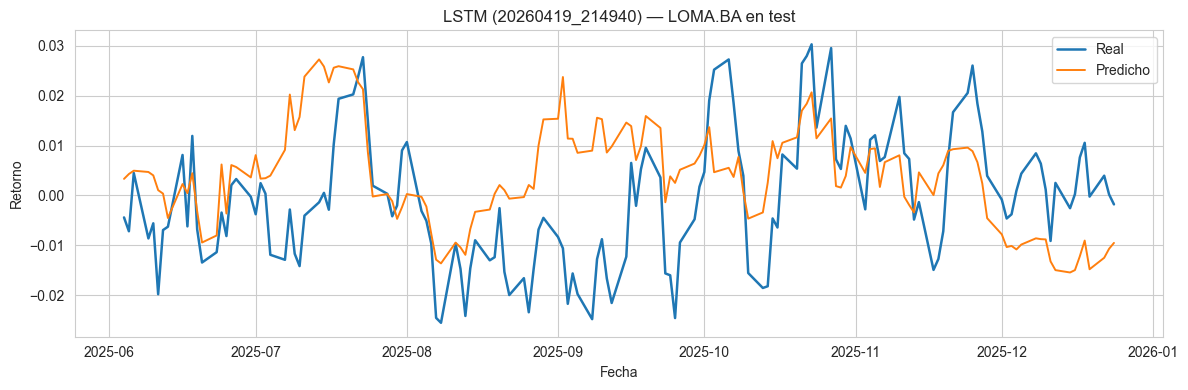

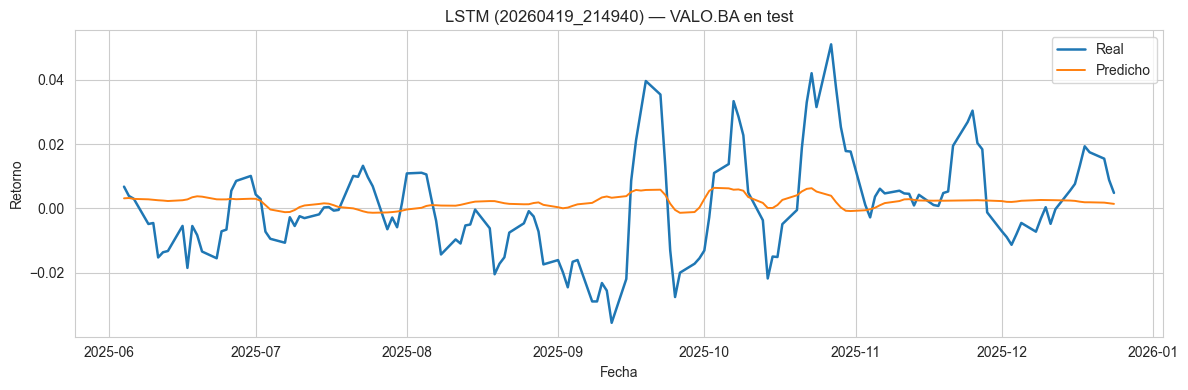

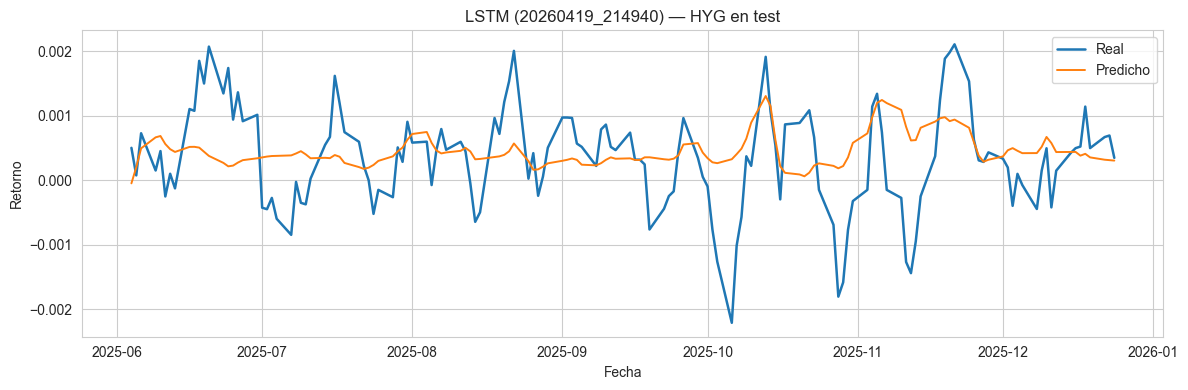

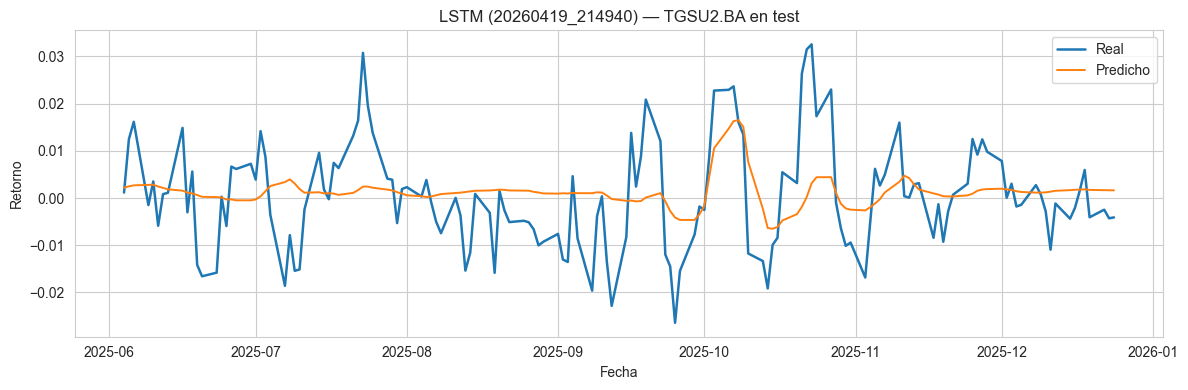

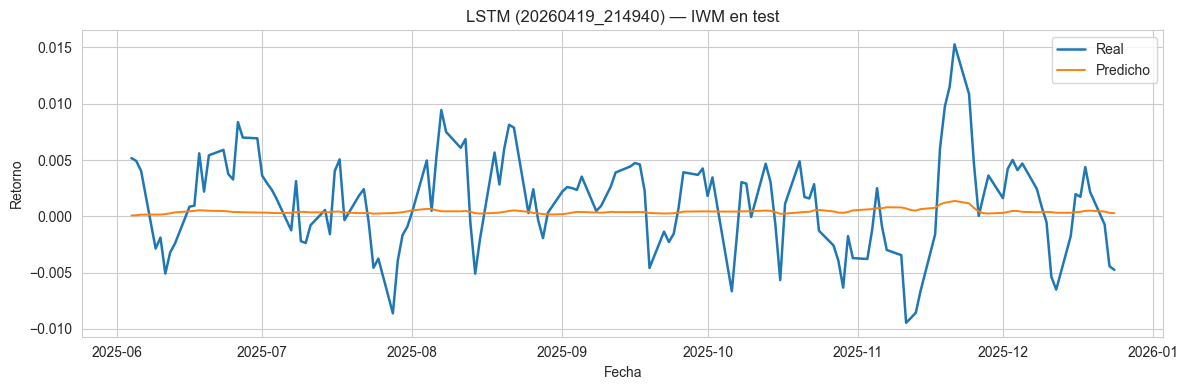

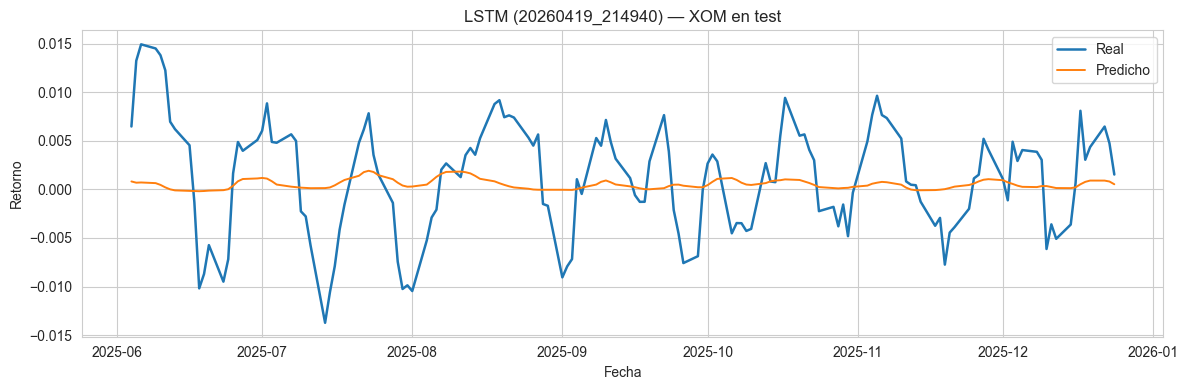

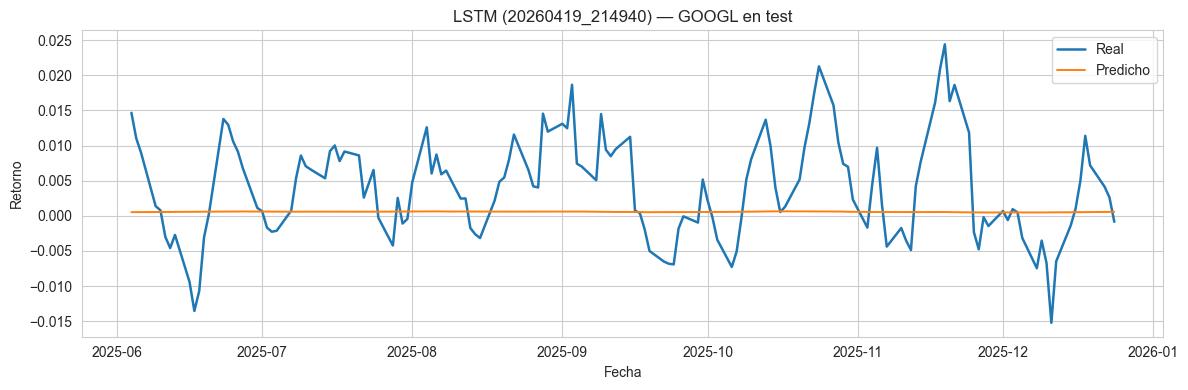

In [76]:
# Gráficos real vs predicho para los tickers que SÍ cumplen el umbral nuevo

# Gráfico real vs predicho para los tickers que sí cumplen el umbral nuevo

tickers_ok = [
    'BBAR.BA',
    'GGAL.BA',
    'YPFD.BA',
    'IEF',
    'KO',
    'V',
    'TSLA',
    'BMA.BA',
    'NVDA',
    'GLD',
    'BRK-B',
    'TLT',
    'VNQ',
    'COME.BA',
    'TXAR.BA',
    'SUPV.BA',
    'JPM',
    'AAPL',
    'META',
    'EDN.BA',
    'CEPU.BA',
    'PAMP.BA',
    'EEM',
    'QQQ',
    'UNH',
    'TGNO4.BA',
    'PEP',
    'MA',
    'ALUA.BA',
    'SPY',
    'MSFT',
    'EFA',
    'AMZN',
    'LOMA.BA',
    'VALO.BA',
    'HYG',
    'TGSU2.BA',
    'IWM',
    'XOM',
    'GOOGL'
]

for TICKER_EXAMPLE in tickers_ok:
    pred_file = LSTM_DIR / LSTM_FINAL_RUN_ID / 'per_ticker' / f'{TICKER_EXAMPLE}_predictions.csv'

    if pred_file.exists():
        pred = pd.read_csv(pred_file, parse_dates=['date'])
        pred_test = pred[pred['split'] == 'test'].copy()

        plt.figure(figsize=(12, 4))
        plt.plot(pred_test['date'], pred_test['y_true'], label='Real', linewidth=1.8)
        plt.plot(pred_test['date'], pred_test['y_pred'], label='Predicho', linewidth=1.4)
        plt.title(f'LSTM ({LSTM_FINAL_RUN_ID}) — {TICKER_EXAMPLE} en test')
        plt.xlabel('Fecha')
        plt.ylabel('Retorno')
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print(f'No existe archivo por ticker: {pred_file}')

In [77]:
# Evaluación GJR-GARCH y chequeo de fallback EWMA
vol_pred = pd.read_csv(ROOT / 'outputs' / 'predictions' / 'volatility_predictions.csv')

source_counts = vol_pred['model_source'].value_counts(dropna=False).rename_axis('model_source').reset_index(name='n_tickers')
source_counts['pct'] = source_counts['n_tickers'] / len(vol_pred)

ewma_fallback_mask = vol_pred['model_source'].astype(str).str.contains('ewma', case=False, na=False)

garch_summary = pd.DataFrame([{
    'n_tickers_total': int(len(vol_pred)),
    'n_gjr_garch': int((vol_pred['model_source'] == 'gjr_garch_t').sum()),
    'n_fallback_ewma': int(ewma_fallback_mask.sum()),
    'vol_pred_min': float(vol_pred['vol_pred'].min()),
    'vol_pred_max': float(vol_pred['vol_pred'].max()),
    'vol_pred_mean': float(vol_pred['vol_pred'].mean()),
}])

print('Fuentes de modelo para volatilidad:')
display(source_counts)

print('\nResumen GJR-GARCH / fallback:')
display(garch_summary)

if ewma_fallback_mask.sum() == 0:
    print('Conclusión: no hubo fallback a EWMA en esta corrida de volatilidad (todas las series salieron con gjr_garch_t).')


Fuentes de modelo para volatilidad:


,model_source,n_tickers,pct
0,gjr_garch_t,40,1.0



Resumen GJR-GARCH / fallback:


,n_tickers_total,n_gjr_garch,n_fallback_ewma,vol_pred_min,vol_pred_max,vol_pred_mean
0,40,40,0,0.001792,0.040676,0.019085


Conclusión: no hubo fallback a EWMA en esta corrida de volatilidad (todas las series salieron con gjr_garch_t).


## 4.3 Impacto en la optimización de portafolios (Classic vs LSTM vs GRJ GARCH)

In [78]:
# Cargar corridas de optimización (run IDs 24,25,26) desde SQLite
# Esta celda funciona aunque DB_PATH/ROOT estén mal seteados.
from pathlib import Path
import os

# 1) Resolver ruta a DB
_db_candidates = []

if 'DB_PATH' in globals() and DB_PATH is not None:
    _db_candidates.append(Path(DB_PATH))

if 'ROOT' in globals() and ROOT is not None:
    _db_candidates.append(Path(ROOT) / 'storage' / 'markowitz_app.db')

env_root = os.getenv('MARKOWITZ_ROOT')
if env_root:
    _db_candidates.append(Path(env_root) / 'storage' / 'markowitz_app.db')

cwd = Path.cwd().resolve()
_db_candidates.extend([
    (cwd / 'storage' / 'markowitz_app.db'),
    *[(p / 'storage' / 'markowitz_app.db') for p in cwd.parents],
])

auto_roots = [
    Path('/workspace/Markowitz'),
    Path('/content/Markowitz'),
    Path.home() / 'Markowitz',
]
_db_candidates.extend([r / 'storage' / 'markowitz_app.db' for r in auto_roots])

resolved_db = next((p for p in _db_candidates if p.exists()), None)
if resolved_db is None:
    raise FileNotFoundError(
        'No se encontró markowitz_app.db. Definí MARKOWITZ_ROOT o exportá la DB local a storage/markowitz_app.db.'
    )

DB_PATH = resolved_db
ROOT = DB_PATH.parent.parent
print(f'DB usada: {DB_PATH}')

# 2) Consulta de corridas
con = sqlite3.connect(DB_PATH)
try:
    run_ids = ','.join(str(v['run_id']) for v in OPTIMIZATION_RUNS.values())
    query = f'''SELECT id, created_at, model_type, max_weight, rf_annual_simple, n_frontier_points,
                       targets_json, metrics_json, comparison_json, block_exposure_json, weights_json, frontier_json
                FROM optimization_runs
                WHERE id IN ({run_ids})
                ORDER BY id'''
    opt_raw = pd.read_sql_query(query, con)
finally:
    con.close()

if opt_raw.empty:
    raise ValueError(
        f'La DB {DB_PATH} no tiene las corridas esperadas ({run_ids}). '
        'Verificá que estés apuntando a la misma base donde guardaste runs 24/25/26.'
    )

id_to_label = {v['run_id']: k for k, v in OPTIMIZATION_RUNS.items()}
id_to_mlflow = {v['run_id']: v['mlflow_run_id'] for v in OPTIMIZATION_RUNS.values()}
opt_raw['escenario'] = opt_raw['id'].map(id_to_label)
opt_raw['mlflow_run_id'] = opt_raw['id'].map(id_to_mlflow)

display(opt_raw[['id', 'escenario', 'mlflow_run_id', 'model_type', 'max_weight', 'rf_annual_simple', 'n_frontier_points']])


DB usada: C:\Users\lucas\OneDrive\Documentos\GitHub\Markowitz\storage\markowitz_app.db


,id,escenario,mlflow_run_id,model_type,max_weight,rf_annual_simple,n_frontier_points
0,24,Classic,461fc6029f5d41639f0b20271c769903,classic,0.15,0.0,80
1,25,LSTM,6f3ec79561ea4be9a9995ca294e4ff6b,classic,0.15,0.0,80
2,26,GRJ GARCH,9a20f4ded8034debb61fadaabcc4ff51,classic,0.15,0.0,80


In [79]:
# Tabla comparativa de métricas de portfolio 'Max Sharpe + Blocks'
rows = []
for _, r in opt_raw.iterrows():
    comparison = json.loads(r['comparison_json']) if r['comparison_json'] else []
    blocks = next((x for x in comparison if str(x.get('portfolio', '')).lower().strip() == 'max sharpe + blocks'), None)
    if blocks is None and len(comparison) > 0:
        blocks = comparison[-1]

    rows.append({
        'escenario': r['escenario'],
        'run_id_db': int(r['id']),
        'mlflow_run_id': r['mlflow_run_id'],
        'model_type': r['model_type'],
        'return_annual_blocks': blocks.get('return_annual') if blocks else np.nan,
        'vol_annual_blocks': blocks.get('vol_annual') if blocks else np.nan,
        'sharpe_annual_blocks': blocks.get('sharpe_annual') if blocks else np.nan,
    })

opt_blocks_metrics = pd.DataFrame(rows).sort_values('sharpe_annual_blocks', ascending=False)
display(opt_blocks_metrics)


,escenario,run_id_db,mlflow_run_id,model_type,return_annual_blocks,vol_annual_blocks,sharpe_annual_blocks
0,Classic,24,461fc6029f5d41639f0b20271c769903,classic,0.118744,0.183948,0.040665
1,LSTM,25,6f3ec79561ea4be9a9995ca294e4ff6b,classic,0.118744,0.183948,0.040665
2,GRJ GARCH,26,9a20f4ded8034debb61fadaabcc4ff51,classic,0.086832,0.303142,0.018044


In [80]:
# Verificación de mismas ponderaciones objetivo por bloque
targets_rows = []
for _, r in opt_raw.iterrows():
    targets = json.loads(r['targets_json']) if r['targets_json'] else {}
    targets_rows.append({'escenario': r['escenario'], **targets})

targets_df = pd.DataFrame(targets_rows)

print('Targets declarados por corrida:')
display(targets_df)
print('Targets de referencia esperados:')
display(pd.DataFrame([{'escenario': 'REFERENCIA', **TARGET_BLOCKS}]))


Targets declarados por corrida:


,escenario,AR,US,FUNDS_EQUITY,FUNDS_BONDS,GOLD
0,Classic,0.18,0.52,0.1,0.08,0.12
1,LSTM,0.18,0.52,0.1,0.08,0.12
2,GRJ GARCH,0.50,0.50,0.0,0.00,0.00


Targets de referencia esperados:


,escenario,AR,US,FUNDS_EQUITY,FUNDS_BONDS,GOLD
0,REFERENCIA,0.2,0.5,0.12,0.1,0.08


In [81]:
# Tabla de pesos (top) para copiar al capítulo 4.3
weights_tables = {}
for _, r in opt_raw.iterrows():
    w = pd.DataFrame(json.loads(r['weights_json']))
    w = w[['ticker', 'block', 'weight']].sort_values('weight', ascending=False).reset_index(drop=True)
    weights_tables[r['escenario']] = w

for scenario, wdf in weights_tables.items():
    print(f'\nTop 15 pesos - {scenario}')
    display(wdf.head(15))



Top 15 pesos - Classic


,ticker,block,weight
0,GLD,GOLD,0.120000
1,AAPL,US,0.034783
2,KO,US,0.034668
3,PEP,US,0.034668
4,UNH,US,0.034667
5,BRK-B,US,0.034667
6,XOM,US,0.034667
7,V,US,0.034666
8,JPM,US,0.034666
9,MA,US,0.034666



Top 15 pesos - LSTM


,ticker,block,weight
0,GLD,GOLD,0.120000
1,AAPL,US,0.034783
2,KO,US,0.034668
3,PEP,US,0.034668
4,UNH,US,0.034667
5,BRK-B,US,0.034667
6,XOM,US,0.034667
7,V,US,0.034666
8,JPM,US,0.034666
9,MA,US,0.034666



Top 15 pesos - GRJ GARCH


,ticker,block,weight
0,AAPL,US,0.033333
1,BBAR.BA,AR,0.033333
2,BMA.BA,AR,0.033333
3,PEP,US,0.033333
4,KO,US,0.033333
5,UNH,US,0.033333
6,XOM,US,0.033333
7,V,US,0.033333
8,MSFT,US,0.033333
9,MA,US,0.033333


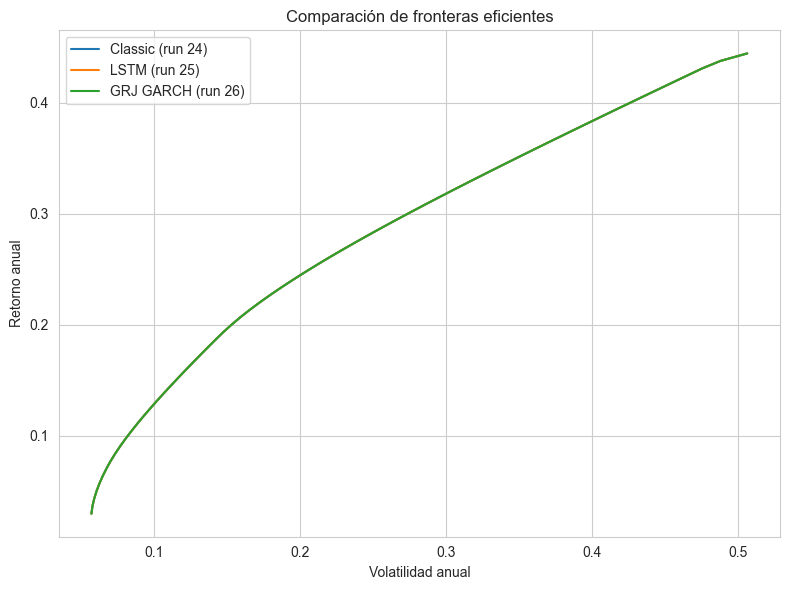

In [82]:
# Comparación de fronteras eficientes
plt.figure(figsize=(8, 6))
for _, r in opt_raw.iterrows():
    frontier = pd.DataFrame(json.loads(r['frontier_json']))
    plt.plot(frontier['vol_annual'], frontier['return_annual'], label=f"{r['escenario']} (run {int(r['id'])})")

plt.title('Comparación de fronteras eficientes')
plt.xlabel('Volatilidad anual')
plt.ylabel('Retorno anual')
plt.legend()
plt.tight_layout()
plt.show()


## 4.4 Discusión de resultados (plantilla guiada)

Usá lo que sale en las tablas anteriores para redactar esta parte:

1. **Modelos predictivos:**
   - Cómo evolucionó el historial de corridas LSTM.
   - Justificación de la corrida definitiva (`20260419_214940`) y sus hiperparámetros.
   - Cuántos activos pasaron el umbral `dir_acc_test > 0.52` y cuántos quedaron con fallback histórico.

2. **Volatilidad (GJR-GARCH):**
   - Confirmar si hubo fallback a EWMA.
   - Si no hubo fallback, explicar que todas las series convergieron bajo `gjr_garch_t`.

3. **Optimización de portafolios:**
   - Comparar rendimiento/riesgo/sharpe de Classic vs LSTM vs GRJ GARCH.
   - Analizar diferencias de pesos y exposición por bloque con targets fijos.

4. **Conclusión práctica:**
   - Qué input (histórico vs IA retornos LSTM vs IA volatilidad GJR) aporta mayor valor en tu configuración de bloques.
